The data has 81 columns which include 23 nominal, 23 ordinal, 14 discrete, and 20 continuous variables - and 1 additional observation identifiers.

Contributors: Albert, Derek, Luis

In [37]:
#Import everything
import pandas as pd
import numpy as np
from sklearn.impute import SimpleImputer
from sklearn.compose import make_column_transformer
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, RidgeCV
from sklearn.preprocessing import StandardScaler, PolynomialFeatures, OneHotEncoder, OrdinalEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, root_mean_squared_error
import matplotlib.pyplot as plt
import seaborn as sns

### Read and inspect data

In [38]:
df = pd.read_csv('train.csv')
print(df.shape)
df.info()

(1200, 81)
<class 'pandas.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1200 non-null   int64  
 1   MSSubClass     1200 non-null   int64  
 2   MSZoning       1200 non-null   str    
 3   LotFrontage    990 non-null    float64
 4   LotArea        1200 non-null   int64  
 5   Street         1200 non-null   str    
 6   Alley          75 non-null     str    
 7   LotShape       1200 non-null   str    
 8   LandContour    1200 non-null   str    
 9   Utilities      1200 non-null   str    
 10  LotConfig      1200 non-null   str    
 11  LandSlope      1200 non-null   str    
 12  Neighborhood   1200 non-null   str    
 13  Condition1     1200 non-null   str    
 14  Condition2     1200 non-null   str    
 15  BldgType       1200 non-null   str    
 16  HouseStyle     1200 non-null   str    
 17  OverallQual    1200 non-null   int64  
 18  OverallC

Get the structure

In [39]:
test = pd.read_csv('test.csv')
test.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition
0,1201,20,RL,71.0,9353,Pave,NaN,Reg,Lvl,AllPub,...,0,0,NaN,NaN,Shed,0,7,2006,Oth,Abnorml
1,1202,60,RL,80.0,10400,Pave,NaN,Reg,Lvl,AllPub,...,0,0,NaN,NaN,NaN,0,3,2009,WD,Normal
2,1203,50,RM,50.0,6000,Pave,NaN,Reg,Lvl,AllPub,...,0,0,NaN,NaN,NaN,0,5,2009,WD,Normal
3,1204,20,RL,75.0,9750,Pave,NaN,Reg,Lvl,AllPub,...,0,0,NaN,NaN,NaN,0,10,2009,WD,Normal
4,1205,20,RL,78.0,10140,Pave,NaN,Reg,Lvl,AllPub,...,0,0,NaN,MnPrv,NaN,0,7,2006,WD,Normal


### Find suitable variables using standard deviations and correlations with housing price

In [40]:
#Handle missing values
num_imputer = SimpleImputer(strategy='mean')
numerical = df.select_dtypes(['int', 'float']).drop(columns=['Id','SalePrice'])
numerical = pd.DataFrame(num_imputer.fit_transform(numerical),
                         columns=numerical.columns,
                         index=numerical.index)

#Calculate beta weights
beta_weights = numerical.corrwith(df['SalePrice']) * numerical.std()
beta_weights.sort_values(ascending=False)
#numerical.corrwith(df['SalePrice']).sort_values(ascending=False)
#numerical.std().sort_values(ascending=False)

LotArea          2833.303553
GrLivArea         383.057659
TotalBsmtSF       269.602613
1stFlrSF          232.105946
BsmtFinSF1        179.324815
2ndFlrSF          152.361527
GarageArea        132.596105
BsmtUnfSF          90.741817
MasVnrArea         88.119186
WoodDeckSF         39.117726
OpenPorchSF        20.724440
YearBuilt          15.721135
GarageYrBlt        11.433018
YearRemodAdd       10.467163
LotFrontage         7.836365
ScreenPorch         6.566173
PoolArea            3.435641
OverallQual         1.091730
TotRmsAbvGrd        0.903299
3SsnPorch           0.624603
GarageCars          0.476551
FullBath            0.315765
Fireplaces          0.294427
BedroomAbvGr        0.150592
HalfBath            0.149810
MoSold              0.125676
BsmtFullBath        0.115104
BsmtHalfBath       -0.004277
KitchenAbvGr       -0.029263
YrSold             -0.052552
OverallCond        -0.092501
BsmtFinSF2         -0.464020
LowQualFinSF       -1.409815
MSSubClass         -3.236019
EnclosedPorch 

`LotArea` has a beta weight of 2833.304 but a correlation (with `SalePrice`) of only 0.267. Inspecting the histogram of this variable, we see that it is very skewed to the right, so we can take the logarithm of this variable to approximately normalize it. This is a strong candidate to include in the regression model.

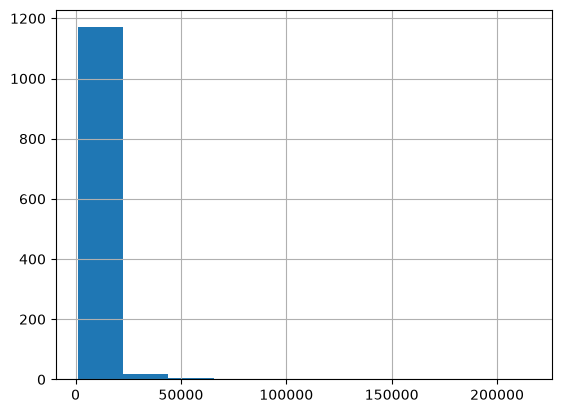

In [41]:
numerical['LotArea'].hist();

Since LotArea is heavily right-skewed, we need to normalize it by applying the natural log of LotArea.

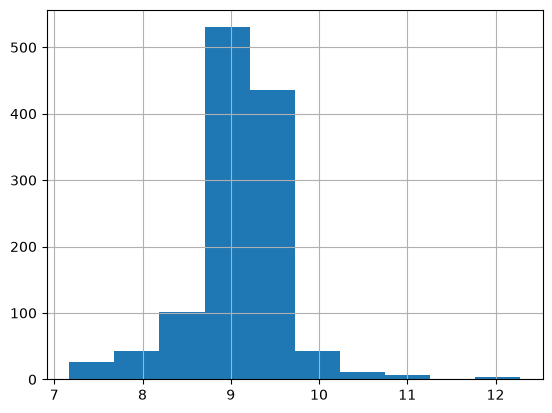

In [42]:
np.log(numerical['LotArea']).hist();

In [43]:
numerical['LogLotArea'] = np.log(numerical['LotArea'])

### Along with LogLotArea we included GrLivArea, BsmtFinSF1, BsmtUnfSF, 1stFlrSF, 2ndFlrSF, GarageArea, YearBuilt, YearRemodAdd, and OverallQual. Each ranks in the top 10 numeric variables by correlation with SalePrice via the .corrwith method or by beta weight. A home that is larger, has more land or has more quality would be expected to have a higher selling price. Homes that were built or remodeled recently are also expected to sell for more.

### Transform and fit data to a model

In [44]:
x = df[['GrLivArea', 'BsmtFinSF1', 'BsmtUnfSF', '1stFlrSF', '2ndFlrSF', 'GarageArea', 'YearBuilt', 'YearRemodAdd', 'OverallQual']]
x['LogLotArea'] = numerical['LogLotArea'];
y = df['SalePrice']


In [45]:
x_train, x_test, y_train, y_test = train_test_split(x,y,test_size=260, random_state = 1)

Handle ordinal variable encoding:

In [46]:
df['OverallQual'].value_counts().index.tolist()

[5, 6, 7, 8, 4, 9, 3, 10, 2, 1]

In [47]:
# missing = df[df.columns[df.isna().sum() > 0]]
# num_missing = missing.select_dtypes(['int', 'float']).columns.tolist()
#

In [48]:
#convert overallqual to ordered numbers from 0-9
vals = [[1, 2, 3, 4, 5, 6, 7, 8, 9, 10]]
ord_encoder = OrdinalEncoder(categories=vals)
ord_cols = ['OverallQual']
transformer = make_column_transformer((ord_encoder, ord_cols),
                                      remainder='passthrough')

In [49]:
#Fit the model
model_pipeline = Pipeline([('transform', transformer), ('model', LinearRegression())])
model_pipeline.fit(x_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('transform', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['GrLivArea','BsmtFinSF1','BsmtUnfSF',...,'YearRemodAdd','OverallQual', 'LogLotArea']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('ordinalencoder', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of

In [50]:
np.sqrt(mean_squared_error(y_test, model_pipeline.predict(x_test)))

np.float64(32738.030312568175)

<Axes: >

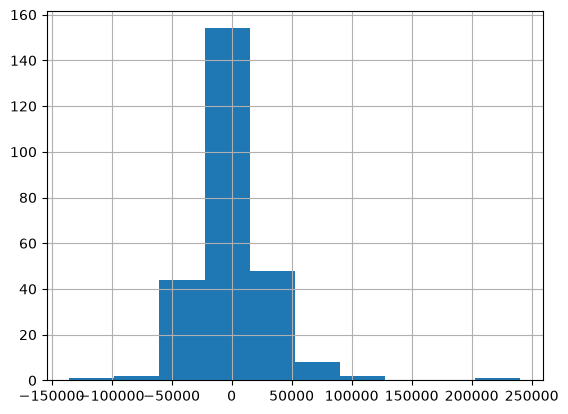

In [51]:
(y_test - model_pipeline.predict(x_test)).hist()

### Test polynomial fits

In [52]:
#Find what degree of polynomial features has the lowest Test RMSE
for i in range(1, 6):
    poly_feats = PolynomialFeatures(degree = i, include_bias = False)
    model_pipeline = Pipeline([('transform', transformer), ('model', poly_feats)])

    x_train_poly = model_pipeline.fit_transform(x_train)
    x_test_poly = model_pipeline.transform(x_test)
    lr = LinearRegression()
    lr.fit(x_train_poly, y_train)
    train_preds = lr.predict(x_train_poly)
    test_preds = lr.predict(x_test_poly)
    print(f'Train RMSE: {np.sqrt(mean_squared_error(y_train, train_preds))}')
    print(f'Test RMSE: {np.sqrt(mean_squared_error(y_test, test_preds))}')
    print('--------------------------------')

Train RMSE: 34503.603295335044
Test RMSE: 32738.030312568182
--------------------------------
Train RMSE: 28308.79165770994
Test RMSE: 30746.23199126802
--------------------------------
Train RMSE: 21077.87623338537
Test RMSE: 36556.24494426895
--------------------------------
Train RMSE: 17844.07143907977
Test RMSE: 87762.11098638142
--------------------------------
Train RMSE: 16043.054834916995
Test RMSE: 311957.1249252111
--------------------------------


In [53]:
# Degree 2 had the lowest test RMSE so fit a 2 degree polynomial regression
poly_feats = PolynomialFeatures(degree = 2, include_bias = False)
model_pipeline = Pipeline([('transform', transformer), ('model', poly_feats)])
x_train_poly = model_pipeline.fit_transform(x_train)
x_test_poly = model_pipeline.transform(x_test)
lr = LinearRegression()
lr.fit(x_train_poly, y_train)
train_preds = lr.predict(x_train_poly)
test_preds = lr.predict(x_test_poly)

<Axes: >

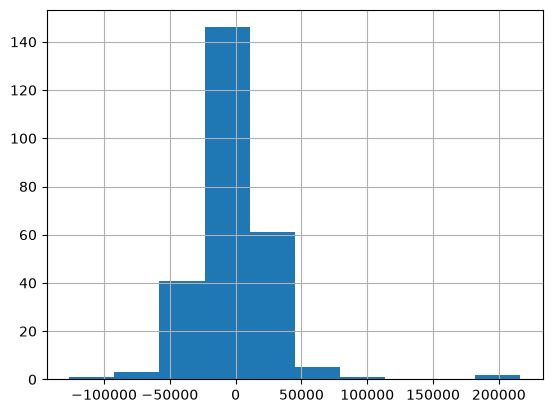

In [54]:
(y_test - test_preds).hist()

In [55]:
# Make the solutions columns and csv
solution = pd.DataFrame({
    'Id': range(len(test_preds)),
    'SalePrice': test_preds
})

print("Row count:", len(solution))
print(solution.head())

solution.to_csv('submission.csv', index=False)